## Homework 4

> [!NOTE]
> This homework uses the pinned 2026 lead-scoring release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.


In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).


In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not. 

In [1]:
# Imports

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```


In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
# Checking for missing values
missing_values = df.isnull().sum()
missing_values

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
# For numerical columns, we can fill missing values with the 0
numerical_cols = df.select_dtypes(include=[np.number]).columns
df[numerical_cols] = df[numerical_cols].fillna(0)

# For categorical columns, we can fill missing values with NA
categorical_cols = df.select_dtypes(include=['str']).columns
df[categorical_cols] = df[categorical_cols].fillna('NA')

In [6]:
# Splitting the data into train and test sets
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
X_train = df_train.drop(columns=['converted'])
y_train = df_train['converted'].values

X_val = df_val.drop(columns=['converted'])
y_val = df_val['converted'].values      

X_test = df_test.drop(columns=['converted'])
y_test = df_test['converted'].values

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [8]:
from sklearn.metrics import roc_auc_score

auc_score_dict = {}
for column in numerical_cols:
    if column != 'converted':
        y_val = df_val['converted'].values
        y_pred = df_val[column].values
        auc_score = roc_auc_score(y_val, y_pred)
        auc_score_dict[column] = auc_score

        if auc_score < 0.5:
            auc_score = roc_auc_score(y_val, -y_pred)
        auc_score_dict[column] = auc_score
    

In [9]:
auc_score_dict

{'annual_income': 0.6130113271009547,
 'number_of_courses_viewed': 0.714398773309591,
 'interaction_count': 0.7631840365369078,
 'lead_score': 0.7833135480041549}

### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [10]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = X_train.to_dict(orient='records')
X_train_ohe = dv.fit_transform(train_dict)
X_val_ohe = dv.transform(X_val.to_dict(orient='records'))
X_test_ohe = dv.transform(X_test.to_dict(orient='records'))

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', random_state=1)

model.fit(X_train_ohe, y_train)

y_val_pred = model.predict_proba(X_val_ohe)[:, 1]

auc_score = roc_auc_score(y_val, y_val_pred)

In [12]:
round(auc_score, 3)

0.732

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Initialize lists to store precision and recall values
precisions = []
recalls = []

# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
thresholds = np.linspace(0, 1, 101)


for i in range(len(thresholds)):
    threshold = thresholds[i]
    y_val_pred_class = (y_val_pred >= threshold).astype(int)
    
    precision = precision_score(y_val, y_val_pred_class, zero_division=0)
    recall = recall_score(y_val, y_val_pred_class, zero_division=0)
    
    precisions.append(precision)
    recalls.append(recall)



In [14]:
precision_recall_df = pd.DataFrame({'threshold': thresholds, 'precision': precisions, 'recall': recalls})

In [15]:
precision_recall_df["difference"] = abs(precision_recall_df["precision"] - precision_recall_df["recall"])


In [16]:
precision_recall_df["difference"].describe()

count    101.000000
mean       0.404704
std        0.242620
min        0.000000
25%        0.273017
50%        0.412237
75%        0.414000
max        0.998294
Name: difference, dtype: float64

In [17]:
min_diff =precision_recall_df[~((precision_recall_df["precision"] == 0) & (precision_recall_df["recall"] == 0))].difference.min()

In [18]:
precision_recall_df[precision_recall_df["difference"] == min_diff]

,threshold,precision,recall,difference
63,0.63,0.732759,0.725256,0.007503


In [19]:
min_diff_threshold = precision_recall_df[precision_recall_df["difference"] == min_diff]["threshold"].iloc[0]

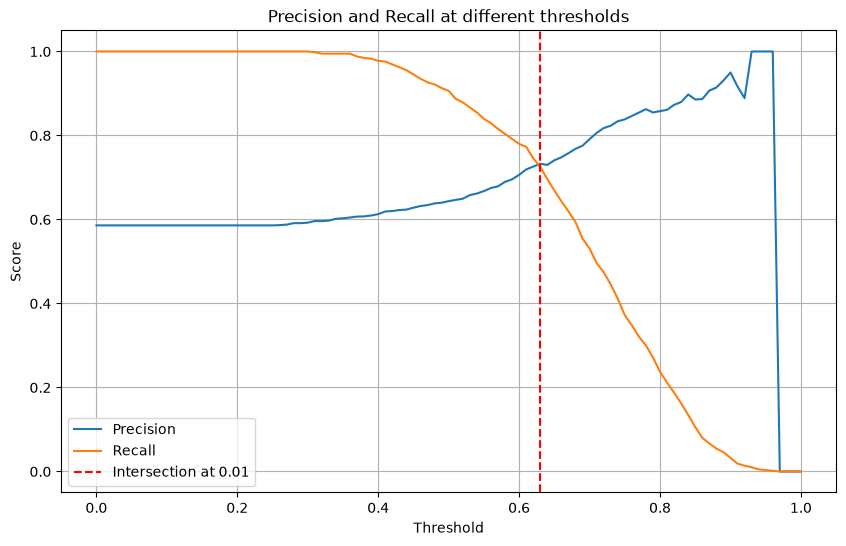

In [20]:
import matplotlib.pyplot as plt

# Plot precision and recall
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')

# Plot vertical line at intersection point
plt.axvline(x=min_diff_threshold, color='r', linestyle='--', label=f'Intersection at {min_diff:.2f}')

# Add labels, title, legend, and grid
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall at different thresholds')
plt.legend()
plt.grid(True)

# Show plot
plt.show()

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [21]:
precision_recall_df ["f1_score"] = 2 * (precision_recall_df["precision"] * precision_recall_df["recall"]) / (precision_recall_df["precision"] + precision_recall_df["recall"])

In [22]:
precision_recall_df[precision_recall_df["f1_score"]==precision_recall_df["f1_score"].max()]

,threshold,precision,recall,difference,f1_score
41,0.41,0.619048,0.976109,0.357062,0.757616


### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [23]:
from sklearn.model_selection import KFold

# Initialize KFold with 5 splits
kf = KFold(n_splits=5, shuffle=True, random_state=1)

In [24]:
kf

KFold(n_splits=5, random_state=1, shuffle=True)

In [25]:
# Try the models for each fold
scores = []
for train_idx, val_idx in kf.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    # X and Y train and val
    X_train_kf = df_train.drop(columns=['converted'])
    y_train_kf = df_train['converted'].values

    X_val_kf = df_val.drop(columns=['converted'])
    y_val_kf = df_val['converted'].values

    # Convert strings
    dv = DictVectorizer(sparse=False)

    X_train_kf_ohe = dv.fit_transform(X_train_kf.to_dict(orient='records'))
    X_val_kf_ohe = dv.transform(X_val_kf.to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_kf_ohe,y_train_kf)

    y_val_pred = model.predict_proba(X_val_kf_ohe)[:, 1]

    score = roc_auc_score(y_val_kf, y_val_pred)    
    scores.append(score)

In [26]:
round(np.std(scores),3)

np.float64(0.007)

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.


In [27]:
C_list = [0.000001, 0.001, 1]

kf = KFold(n_splits=5, shuffle=True, random_state=1)

for c in C_list:
    # Try the models for each fold
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        # X and Y train and val
        X_train_kf = df_train.drop(columns=['converted'])
        y_train_kf = df_train['converted'].values

        X_val_kf = df_val.drop(columns=['converted'])
        y_val_kf = df_val['converted'].values

        # Convert strings
        dv = DictVectorizer(sparse=False)

        X_train_kf_ohe = dv.fit_transform(X_train_kf.to_dict(orient='records'))
        X_val_kf_ohe = dv.transform(X_val_kf.to_dict(orient='records'))

        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_train_kf_ohe,y_train_kf)

        y_val_pred = model.predict_proba(X_val_kf_ohe)[:, 1]

        score = roc_auc_score(y_val_kf, y_val_pred)    
        scores.append(score)
    
    print('C=%s %.3f +- %.3f' % (c, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
